# **Image Classification Pet Animal Model Deployment**

# **Nama : Doni Firmansyah**

In [ ]:
# @markdown **Import Library**

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.preprocessing.image import ImageDataGenerator
from keras.preprocessing import image
import os
from google.colab import files
import pathlib

In [ ]:
# @markdown **Collecting Data** :\
# @markdown Dataset yang digunakan adalah dari https://www.kaggle.com/datasets/dhondoi/pet-animal

!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d dhondoi/pet-animal -p pet_animal --unzip

  1% 25.0M/1.72G [00:01<01:19, 22.9MB/s]

In [ ]:
# @markdown **Collecting Data** :\
# @markdown Checking Total Dataset

ANIMAL = []

print("Before Splitting")

DIR = "pet_animal"
TOTAL_OUTPUT = len(os.listdir(DIR))
totalAll = 0

for labelName in os.listdir(DIR):
  ANIMAL.append(labelName)

  dirLabel = os.path.join(DIR, labelName)
  total = len([name for name in os.listdir(dirLabel) if os.path.isfile(os.path.join(dirLabel, name))])

  print(f"Count Image {labelName} : {total}")

  totalAll+=total

print("---------------")
print(f"Total Image : {totalAll}")
print(f"Label Names : {ANIMAL}")
print("---------------")

Before Splitting
Count Image horse : 1500
Count Image chicken : 1500
Count Image hamster : 1500
Count Image cat : 1500
Count Image rabbit : 1500
Count Image bird : 1500
Count Image goose : 1500
Count Image cow : 1500
Count Image fish : 1500
Count Image dog : 1500
Count Image sheep : 1500
Total Image : 16500
Label Names : ['horse', 'chicken', 'hamster', 'cat', 'rabbit', 'bird', 'goose', 'cow', 'fish', 'dog', 'sheep']
---------------


In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Image Augmentation

trainIDG = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.1,
    shear_range=0.2,
    fill_mode="nearest",
    validation_split=0.2
)
validationIDG = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=0.2
)

In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Creating Callback

class CustomCallback(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):
        if logs.get("accuracy") > 0.92 and logs.get("val_accuracy") > 0.92:
            print(f"Training and Validation on epoch {epoch+1} get minimum accuracy (92%) : Train {logs.get('accuracy'):.2f} Validation {logs.get('val_accuracy'):.2f}")
            self.model.stop_training = True

In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Modelling

WIDTH = 64
HEIGHT = 64

model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", input_shape=(WIDTH, HEIGHT, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.7),
    tf.keras.layers.Dense(TOTAL_OUTPUT, activation="softmax")]
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 62, 62, 32)        896       
                                                                 
 conv2d_1 (Conv2D)           (None, 60, 60, 32)        9248      
                                                                 
 max_pooling2d (MaxPooling2  (None, 30, 30, 32)        0         
 D)                                                              
                                                                 
 dropout (Dropout)           (None, 30, 30, 32)        0         
                                                                 
 conv2d_2 (Conv2D)           (None, 28, 28, 64)        18496     
                                                                 
 conv2d_3 (Conv2D)           (None, 26, 26, 64)        36928     
                                                        

In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Generate Train and Validation Dataset

BATCH_SIZE = 32

print("After Splitting Using Image Data Generator")
print("\nDataset Train")
trainDataset = trainIDG.flow_from_directory(DIR,
                                            class_mode='categorical',
                                            target_size=(WIDTH, HEIGHT),
                                            subset="training",
                                            batch_size=BATCH_SIZE,
                                            seed=42
                                            )

print("\nDataset Validation")
validationDataset = validationIDG.flow_from_directory(DIR,
                                                      class_mode='categorical',
                                                      target_size=(WIDTH, HEIGHT),
                                                      subset="validation",
                                                      batch_size=BATCH_SIZE,
                                                      seed=42
                                                      )
print("---------------")

After Splitting Using Image Data Generator

Dataset Train
Found 13200 images belonging to 11 classes.

Dataset Validation
Found 3300 images belonging to 11 classes.
---------------


In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Compiler for Model

LEARNING_RATE = 0.001

model.compile(loss='categorical_crossentropy',
              optimizer=tf.optimizers.Adam(learning_rate=LEARNING_RATE),
              metrics=['accuracy'])

In [ ]:
# @markdown **Processing Data** :\
# @markdown Fitting

EPOCH = 100

history = model.fit(trainDataset,
                    epochs=EPOCH,
                    verbose=2,
                    validation_data=validationDataset,
                    callbacks=[CustomCallback()]
                    # steps_per_epoch=2,
                    # validation_steps=2
                    )

Epoch 1/100
413/413 - 309s - loss: 2.6956 - accuracy: 0.2236 - val_loss: 2.2765 - val_accuracy: 0.2306 - 309s/epoch - 748ms/step
Epoch 2/100
413/413 - 330s - loss: 2.0942 - accuracy: 0.3112 - val_loss: 8.9323 - val_accuracy: 0.1742 - 330s/epoch - 798ms/step
Epoch 3/100
413/413 - 322s - loss: 1.9712 - accuracy: 0.3424 - val_loss: 2.4167 - val_accuracy: 0.3055 - 322s/epoch - 779ms/step
Epoch 4/100
413/413 - 328s - loss: 1.7971 - accuracy: 0.4004 - val_loss: 4.0124 - val_accuracy: 0.2379 - 328s/epoch - 793ms/step
Epoch 5/100
413/413 - 322s - loss: 1.7370 - accuracy: 0.4230 - val_loss: 2.2256 - val_accuracy: 0.2748 - 322s/epoch - 779ms/step
Epoch 6/100
413/413 - 304s - loss: 1.6253 - accuracy: 0.4520 - val_loss: 1.8036 - val_accuracy: 0.4121 - 304s/epoch - 736ms/step
Epoch 7/100
413/413 - 308s - loss: 1.5680 - accuracy: 0.4791 - val_loss: 2.0163 - val_accuracy: 0.3827 - 308s/epoch - 745ms/step
Epoch 8/100
413/413 - 314s - loss: 1.5159 - accuracy: 0.4955 - val_loss: 1.8607 - val_accuracy: 0

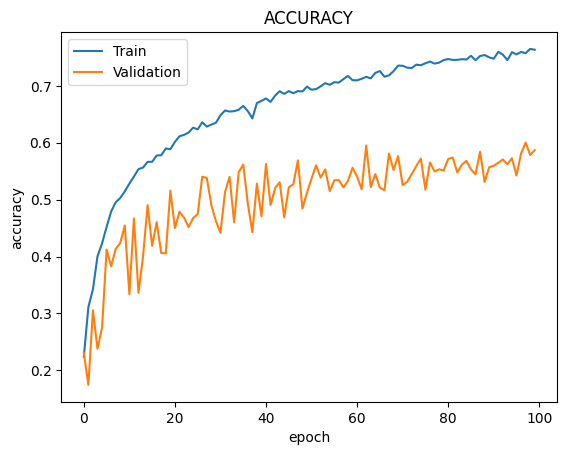

In [ ]:
# @markdown **Post-Processing Data** :\
# @markdown Accuracy Visualization Result

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('ACCURACY')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

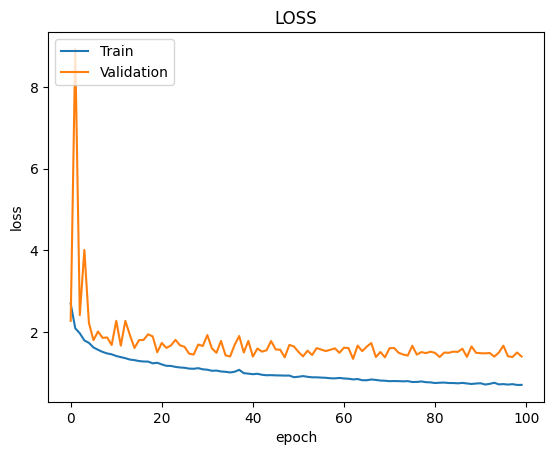

In [ ]:
# @markdown **Post-Processing Data** :\
# @markdown Loss Visualization Result

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('LOSS')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
# @markdown **Post-Processing Data** :\
# @markdown Predict

# uploaded = files.upload()

# for fn in uploaded.keys():
#   path = fn
#   img = image.load_img(path, target_size =(150,150))
#   plt.imshow(img)
#   plt.show()
#   x = image.img_to_array(img)
#   x = np.expand_dims(x, axis=0)

#   images = np.vstack([x])
#   classes = model.predict(images, batch_size=BATCH_SIZE)

# numbClass = np.argmax(classes, axis=1)
# print('Predicted class: ', ANIMAL_DICT[numbClass[0]])

#   print(fn)
#   print(classes)
  # if classes[0,0]!=0:
  #   print('Dog')
  # else:
  #   print('Cat')

In [ ]:
# @markdown **Post-Processing Data** :\
# @markdown Saving Model

# exportDir = 'saved_cnn_model/'
# tf.saved_model.save(model, exportDir)


# converter = tf.lite.TFLiteConverter.from_saved_model(exportDir)
# tfLite = converter.convert()


# tfLiteFile = pathlib.Path('pet_animal.tflite')
# tfLiteFile.write_bytes(tfLite)